In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# Plotting configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

# Relative paths
RAW_DIR = Path("../data/raw").resolve()
OUTPUTS_CLEANING = Path("../outputs/cleaning").resolve()
OUTPUTS_CLEANING.mkdir(parents=True, exist_ok=True)

print(f"Raw data directory: {RAW_DIR}")
print(f"Outputs cleaning directory: {OUTPUTS_CLEANING}")

Raw data directory: C:\Users\hitan\OneDrive\Desktop\flock_energy_assign\data\raw
Outputs cleaning directory: C:\Users\hitan\OneDrive\Desktop\flock_energy_assign\outputs\cleaning


In [2]:
target_raw = RAW_DIR / "RAW_House1_Part1.csv"
assert target_raw.exists(), f"Raw file {target_raw} not found!"

# Column schema: Time, Unix, Aggregate, Appliance1..Appliance9
col_names = ["Time", "Unix", "Aggregate"] + [f"Appliance{i}" for i in range(1, 10)]

print(f"Loading raw records from {target_raw.name}...")
df_raw = pd.read_csv(target_raw, nrows=350000, header=0, names=col_names)
print(f"Loaded DataFrame shape: {df_raw.shape}")
df_raw.head()

Loading raw records from RAW_House1_Part1.csv...


Loaded DataFrame shape: (350000, 12)


,Time,Unix,Aggregate,Appliance1,Appliance2,Appliance3,Appliance4,Appliance5,Appliance6,Appliance7,Appliance8,Appliance9
0,2013-10-09 14:06:17,1381327577,523,74,0,69,0,0,0,0,0,1
1,2013-10-09 14:06:31,1381327591,526,75,0,69,0,0,0,0,0,1
2,2013-10-09 14:06:46,1381327606,540,74,0,68,0,0,0,0,0,1
3,2013-10-09 14:07:01,1381327621,532,74,0,68,0,0,0,0,0,1
4,2013-10-09 14:07:15,1381327634,540,74,0,69,0,0,0,0,0,1


In [3]:
df_raw['DateTime'] = pd.to_datetime(df_raw['Time'], errors='coerce')
invalid_dates = df_raw['DateTime'].isna().sum()

print("--- Timestamp Parsing Audit ---")
print(f"Total rows inspected:  {len(df_raw):,}")
print(f"Invalid / NaT count:   {invalid_dates}")
print(f"Start timestamp:       {df_raw['DateTime'].min()}")
print(f"End timestamp:         {df_raw['DateTime'].max()}")

# Monotonicity
is_monotonic = df_raw['DateTime'].is_monotonic_increasing
time_deltas = df_raw['DateTime'].diff().dt.total_seconds()
retrograde_steps = (time_deltas < 0).sum()
print(f"Strictly monotonic increasing: {is_monotonic}")
print(f"Retrograde steps (dt < 0):     {retrograde_steps}")

--- Timestamp Parsing Audit ---
Total rows inspected:  350,000
Invalid / NaT count:   0
Start timestamp:       2013-10-09 14:06:17
End timestamp:         2013-11-03 01:45:44
Strictly monotonic increasing: False
Retrograde steps (dt < 0):     1


In [4]:
dup_mask = df_raw['DateTime'].duplicated(keep=False)
total_dups = dup_mask.sum()
print(f"Rows with duplicate timestamps: {total_dups:,} ({total_dups / len(df_raw) * 100:.2f}%)")

# Example duplicate cluster
sample_dup_time = df_raw.loc[dup_mask, 'DateTime'].iloc[0]
print(f"\nExample duplicate cluster at {sample_dup_time}:")
df_raw[df_raw['DateTime'] == sample_dup_time][['DateTime', 'Aggregate', 'Appliance5', 'Appliance6']]

Rows with duplicate timestamps: 17,949 (5.13%)

Example duplicate cluster at 2013-10-09 14:40:31:


,DateTime,Aggregate,Appliance5,Appliance6
336,2013-10-09 14:40:31,920,0,0
337,2013-10-09 14:40:31,920,0,0


In [5]:
df_dedup_sorted = df_raw.drop_duplicates('DateTime').sort_values('DateTime')
intervals = df_dedup_sorted['DateTime'].diff().dt.total_seconds().dropna()

print("--- Sampling Interval Statistics (Seconds) ---")
print(f"Median: {intervals.median():.1f} s | Mean: {intervals.mean():.2f} s | Min: {intervals.min():.1f} s | Max: {intervals.max():.1f} s")
print(f"<= 10s (Nominal):      {(intervals <= 10).sum():,} ({(intervals <= 10).mean()*100:.2f}%)")
print(f"10s - 60s (Jitter):    {((intervals > 10) & (intervals <= 60)).sum():,} ({((intervals > 10) & (intervals <= 60)).mean()*100:.2f}%)")
print(f"> 3 min (Outages):     {(intervals > 180).sum():,} ({(intervals > 180).mean()*100:.2f}%)")

--- Sampling Interval Statistics (Seconds) ---
Median: 3.0 s | Mean: 6.21 s | Min: 1.0 s | Max: 4363.0 s
<= 10s (Nominal):      222,928 (65.42%)
10s - 60s (Jitter):    117,769 (34.56%)
> 3 min (Outages):     46 (0.01%)


In [6]:
power_channels = ["Aggregate"] + [f"Appliance{i}" for i in range(1, 10)]
outlier_list = []

for ch in power_channels:
    vals = pd.to_numeric(df_raw[ch], errors='coerce')
    neg_count = (vals < 0).sum()
    limit = 15000.0 if ch == "Aggregate" else 4000.0
    spikes = (vals > limit).sum()
    outlier_list.append({
        "Channel": ch,
        "Min (W)": vals.min(),
        "Max (W)": vals.max(),
        "Negative (<0W)": neg_count,
        f"Spikes (>{int(limit)}W)": spikes
    })

df_outlier_summary = pd.DataFrame(outlier_list)
df_outlier_summary

,Channel,Min (W),Max (W),Negative (<0W),Spikes (>15000W),Spikes (>4000W)
0,Aggregate,98,11445,0,0.0,NaN
1,Appliance1,0,32767,0,NaN,12.0
2,Appliance2,0,8192,0,NaN,2.0
3,Appliance3,0,1024,0,NaN,0.0
4,Appliance4,0,2693,0,NaN,0.0
5,Appliance5,0,2555,0,NaN,0.0
6,Appliance6,0,8192,0,NaN,2.0
7,Appliance7,0,57,0,NaN,0.0
8,Appliance8,0,65549,0,NaN,5.0
9,Appliance9,0,1,0,NaN,0.0


In [7]:
def clean_house1_pipeline(df_input, max_interp_mins=3):
    df = df_input.copy()
    df['DateTime'] = pd.to_datetime(df['Time'], errors='coerce')
    df = df.dropna(subset=['DateTime']).sort_values('DateTime')
    
    power_cols = ['Aggregate'] + [f'Appliance{i}' for i in range(1, 10)]
    for c in power_cols:
        df[c] = pd.to_numeric(df[c], errors='coerce')
        
    # Deduplicate via mean
    df_dedup = df.groupby('DateTime')[power_cols].mean()
    
    # Bounding
    for c in power_cols:
        df_dedup.loc[df_dedup[c] < 0, c] = 0.0
        limit = 15000.0 if c == 'Aggregate' else 4000.0
        df_dedup.loc[df_dedup[c] > limit, c] = np.nan
        
    # 1-minute resampling
    df_1m = df_dedup.resample('1min').mean()
    
    # Gap interpolation <= 3 min; flag longer as outage
    df_clean = df_1m.interpolate(method='time', limit=max_interp_mins, limit_direction='forward')
    df_clean['is_outage'] = df_clean['Aggregate'].isna()
    
    # Rename channels for House 1
    rename_h1 = {
        'Appliance1': 'App_Fridge',
        'Appliance2': 'App_Freezer_1',
        'Appliance3': 'App_Freezer_2',
        'Appliance4': 'App_Washer_Dryer',
        'Appliance5': 'App_Washing_Machine',
        'Appliance6': 'App_Dishwasher',
        'Appliance7': 'App_Computer',
        'Appliance8': 'App_Television',
        'Appliance9': 'App_Electric_Heater'
    }
    df_clean = df_clean.rename(columns=rename_h1)
    return df_clean

df_h1_cleaned = clean_house1_pipeline(df_raw)
print(f"Cleaned 1-minute dataset shape: {df_h1_cleaned.shape}")
print(f"Outage bins: {df_h1_cleaned['is_outage'].sum():,} ({df_h1_cleaned['is_outage'].mean()*100:.2f}%)")
df_h1_cleaned.head()

Cleaned 1-minute dataset shape: (35260, 11)
Outage bins: 458 (1.30%)


,Aggregate,App_Fridge,App_Freezer_1,App_Freezer_2,App_Washer_Dryer,App_Washing_Machine,App_Dishwasher,App_Computer,App_Television,App_Electric_Heater,is_outage
DateTime,,,,,,,,,,,
2013-10-09 14:06:00,529.666667,74.333333,0.0,68.666667,0.0,0.0,0.0,0.0,0.0,1.0,False
2013-10-09 14:07:00,543.875000,73.875000,0.0,68.750000,0.0,0.0,0.0,0.0,0.0,1.0,False
2013-10-09 14:08:00,578.000000,73.100000,0.0,41.900000,0.0,0.0,0.0,0.0,0.0,1.0,False
2013-10-09 14:09:00,638.300000,72.800000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,1.0,False
2013-10-09 14:10:00,800.200000,72.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,1.0,False


Saved figure to C:\Users\hitan\OneDrive\Desktop\flock_energy_assign\outputs\cleaning\house1_before_after_cleaning.png


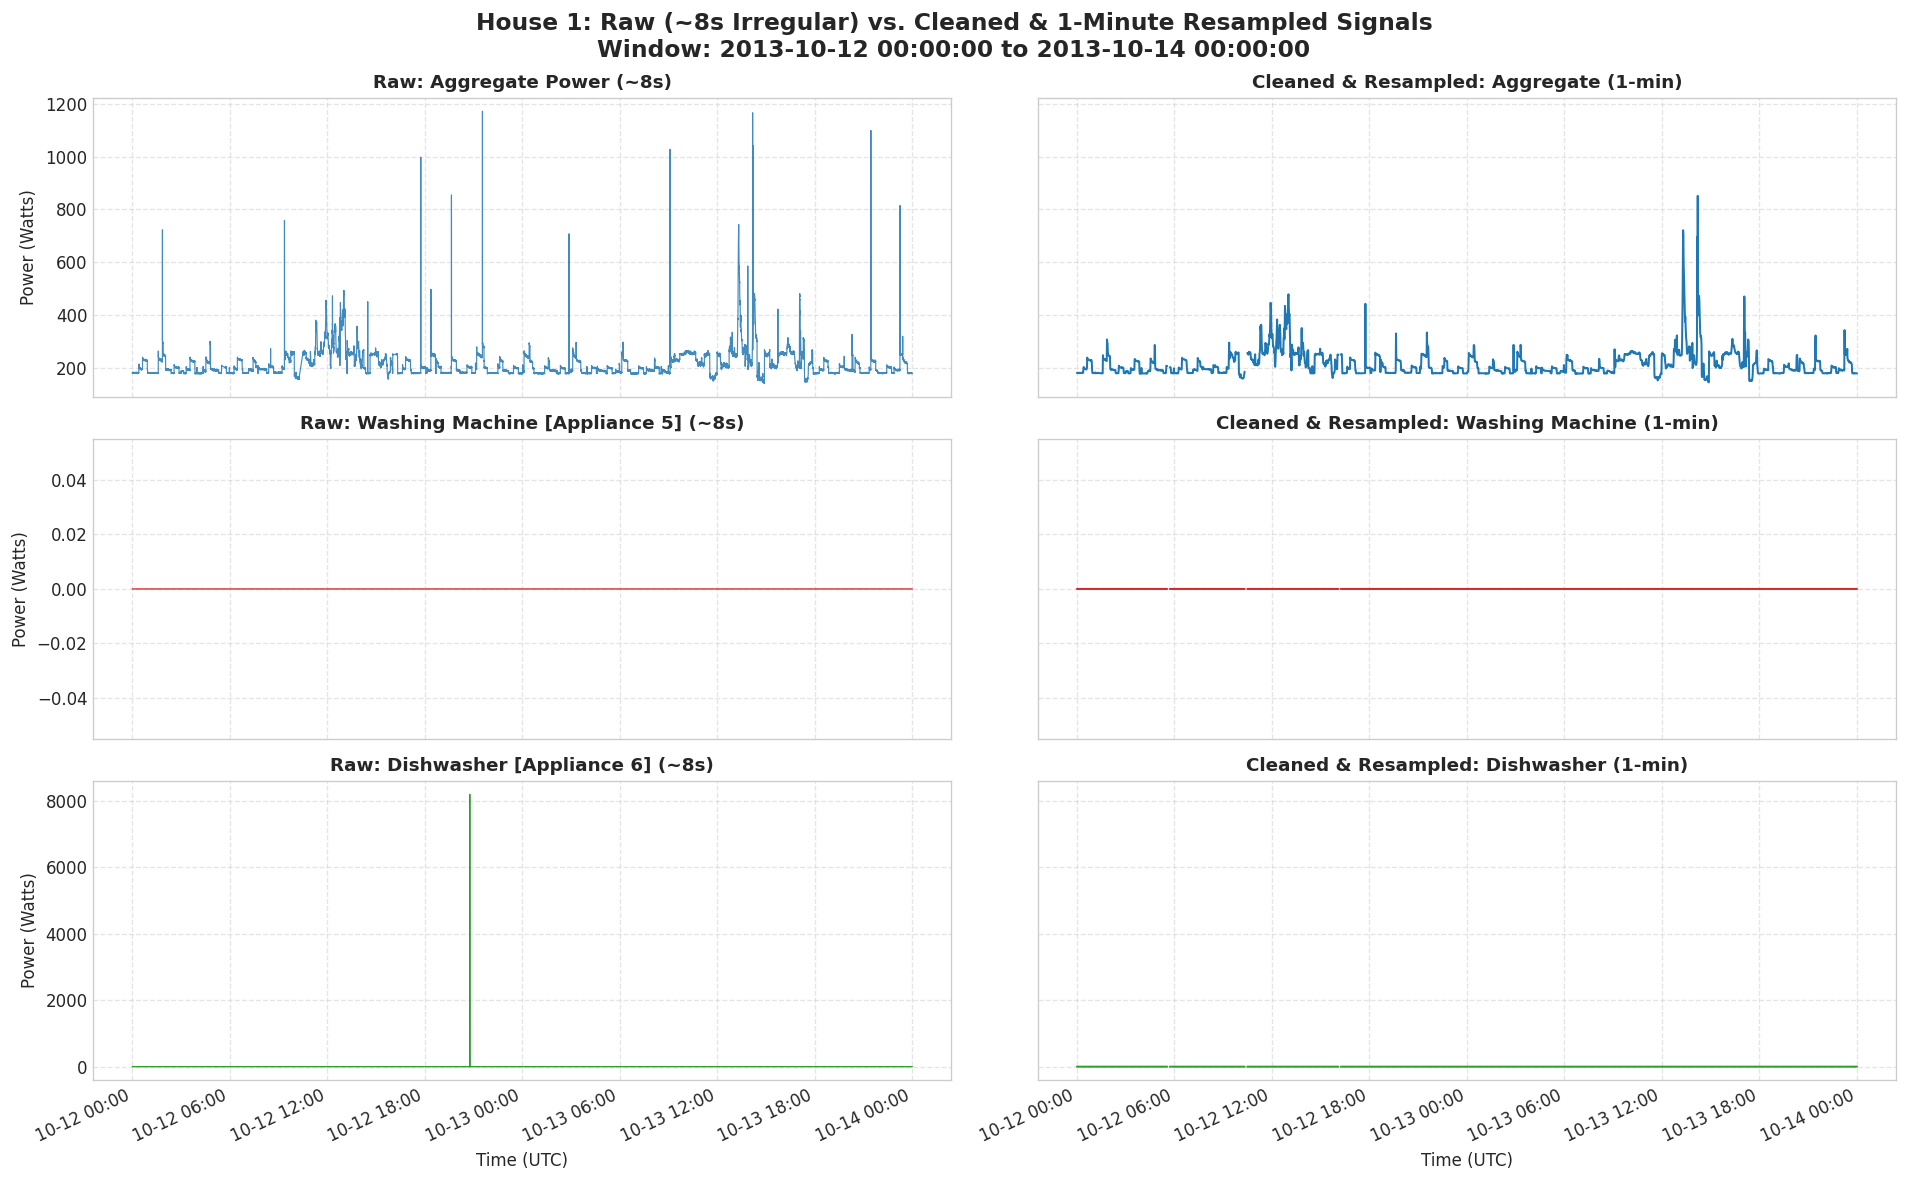

In [8]:
# 48-hour comparison window
sample_start = "2013-10-12 00:00:00"
sample_end   = "2013-10-14 00:00:00"

raw_slice = df_raw[(df_raw['DateTime'] >= sample_start) & (df_raw['DateTime'] <= sample_end)]
clean_slice = df_h1_cleaned.loc[sample_start:sample_end]

fig, axes = plt.subplots(3, 2, figsize=(16, 10), sharex='col', sharey='row')
fig.suptitle(
    f"House 1: Raw (~8s Irregular) vs. Cleaned & 1-Minute Resampled Signals\nWindow: {sample_start} to {sample_end}",
    fontsize=14, fontweight='bold', y=0.98
)

c_agg, c_wm, c_dw = "#1f77b4", "#d62728", "#2ca02c"

# RAW PLOTS
axes[0, 0].plot(raw_slice['DateTime'], raw_slice['Aggregate'], color=c_agg, lw=0.7, alpha=0.85)
axes[0, 0].set_title("Raw: Aggregate Power (~8s)", fontsize=11, fontweight='semibold')
axes[0, 0].set_ylabel("Power (Watts)")
axes[0, 0].grid(True, linestyle="--", alpha=0.5)

axes[1, 0].plot(raw_slice['DateTime'], raw_slice['Appliance5'], color=c_wm, lw=0.8)
axes[1, 0].set_title("Raw: Washing Machine [Appliance 5] (~8s)", fontsize=11, fontweight='semibold')
axes[1, 0].set_ylabel("Power (Watts)")
axes[1, 0].grid(True, linestyle="--", alpha=0.5)

axes[2, 0].plot(raw_slice['DateTime'], raw_slice['Appliance6'], color=c_dw, lw=0.8)
axes[2, 0].set_title("Raw: Dishwasher [Appliance 6] (~8s)", fontsize=11, fontweight='semibold')
axes[2, 0].set_ylabel("Power (Watts)")
axes[2, 0].set_xlabel("Time (UTC)")
axes[2, 0].grid(True, linestyle="--", alpha=0.5)

# CLEANED PLOTS
axes[0, 1].plot(clean_slice.index, clean_slice['Aggregate'], color=c_agg, lw=1.2)
axes[0, 1].set_title("Cleaned & Resampled: Aggregate (1-min)", fontsize=11, fontweight='semibold')
axes[0, 1].grid(True, linestyle="--", alpha=0.5)

axes[1, 1].plot(clean_slice.index, clean_slice['App_Washing_Machine'], color=c_wm, lw=1.2)
axes[1, 1].set_title("Cleaned & Resampled: Washing Machine (1-min)", fontsize=11, fontweight='semibold')
axes[1, 1].grid(True, linestyle="--", alpha=0.5)

axes[2, 1].plot(clean_slice.index, clean_slice['App_Dishwasher'], color=c_dw, lw=1.2)
axes[2, 1].set_title("Cleaned & Resampled: Dishwasher (1-min)", fontsize=11, fontweight='semibold')
axes[2, 1].set_xlabel("Time (UTC)")
axes[2, 1].grid(True, linestyle="--", alpha=0.5)

for ax in axes.flat:
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d %H:%M'))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=25, ha='right')

plt.tight_layout()
fig_clean_path = OUTPUTS_CLEANING / "house1_before_after_cleaning.png"
fig.savefig(fig_clean_path, dpi=200, bbox_inches="tight")
print(f"Saved figure to {fig_clean_path}")
plt.show()